**Objective:** In Part 2 of Homework 4, we focus on advanced techniques, such as regularization, in the Logistic Regression classification algorithm.


# Part I: Load and Explore the Dataset (Total: 6 pts)

1) Load the dataset `student.csv` into a pandas DataFrame.

In [1]:
import pandas as pd
import numpy as np
data = pd.read_csv('student.csv', index_col=0)
data.head()

,default,student,balance,income
1,No,No,729.526495,44361.625074
2,No,Yes,817.180407,12106.134700
3,No,No,1073.549164,31767.138947
4,No,No,529.250605,35704.493935
5,No,No,785.655883,38463.495879


2) Apply one-hot encoding to convert `default` and `student` into categorical variables. (2 pts)

In [2]:
# Convert default and student into categorical variables using built-in one-hot encoding


# YOUR CODE
data = pd.get_dummies(data, columns=['default', 'student'], dtype=int)

# DO NOT MODIFY THE CODE BELOW
data = data.drop('default_No', axis=1)
data = data.drop('student_No', axis=1)


data.head()

,balance,income,default_Yes,student_Yes
1,729.526495,44361.625074,0,0
2,817.180407,12106.134700,0,1
3,1073.549164,31767.138947,0,0
4,529.250605,35704.493935,0,0
5,785.655883,38463.495879,0,0


3.1) Create boxplots of all of the variables. (2 pts)

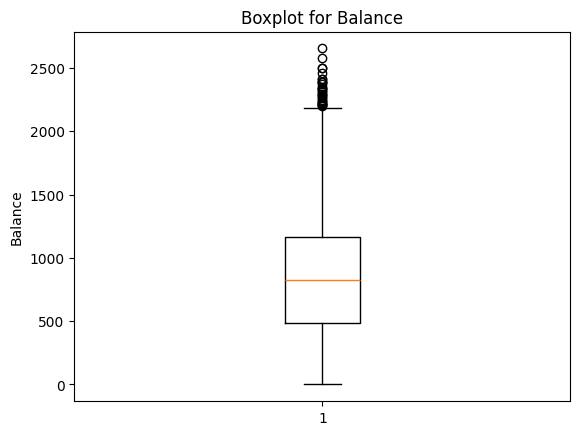

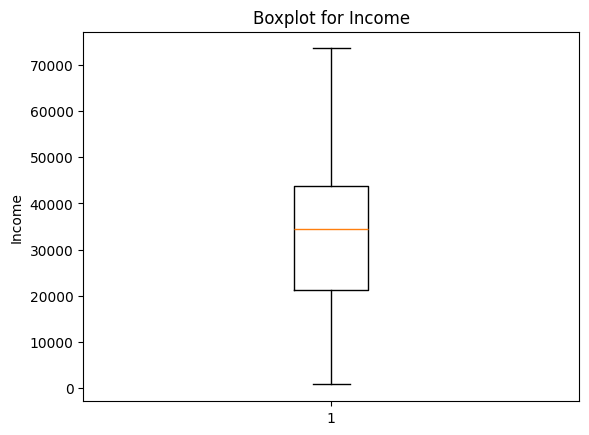

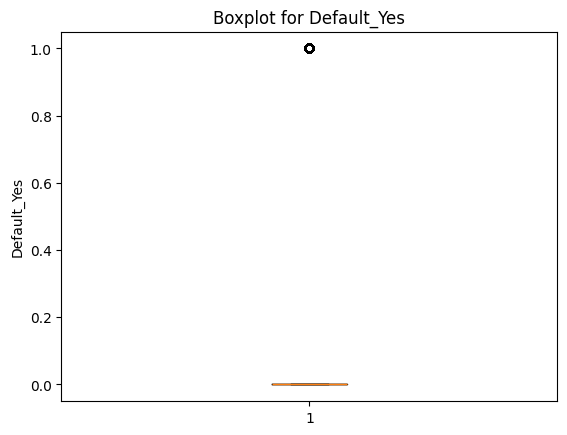

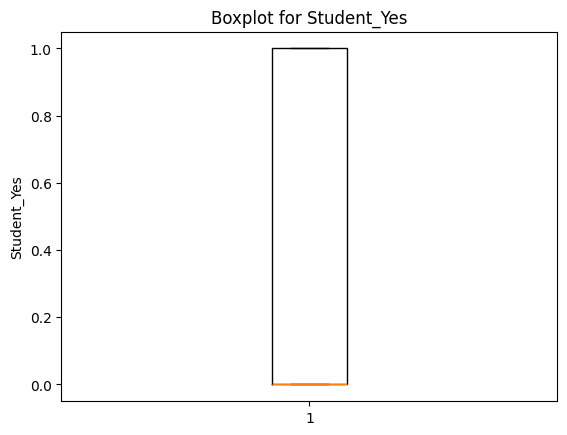

In [3]:
# Create boxplots of all variables
import matplotlib.pyplot as plt


for variable in data.columns:
    plt.figure()
    plt.boxplot(data[variable])

    variable = variable.title()
    plt.title(f'Boxplot for {variable}')
    plt.ylabel(variable)
    plt.show()

3.2) Create a scatter plot of (balance, income), coloring each point red if `default` is Yes and blue if No. (2 pts)

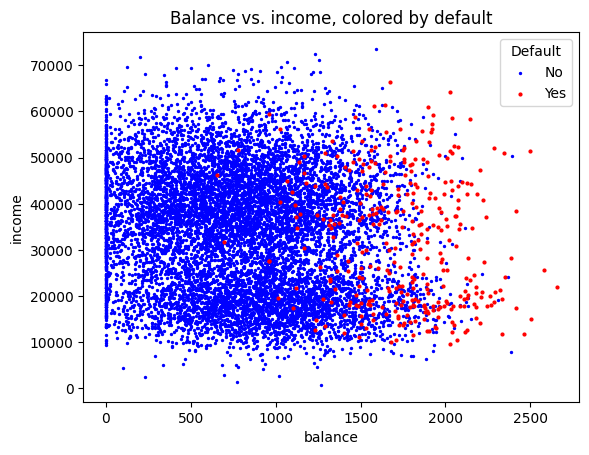

In [4]:
# Create a scatter plot of (balance, income): red if default is Yes, blue if No
# YOUR CODE
data_no = data[data['default_Yes'] == 0]
plt.scatter(data_no['balance'], data_no['income'], color='blue', label='No', s=2)

data_yes = data[data['default_Yes'] == 1]
plt.scatter(data_yes['balance'], data_yes['income'], color='red', label='Yes', s=4)

plt.xlabel('balance')
plt.ylabel('income')
plt.title('Balance vs. income, colored by default')
plt.legend(title='Default')
plt.show()

# Part II: Train a Logistic Regression Model (Total: 22 pts)

4.1) Using only the student records, train a Logistic Regression model to predict whether a student defaults on their loan, based solely on the `balance` and `income` variables. Set `penalty='l2'` when creating the LogisticRegression object. (6 pts)

In [5]:
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Keep only the student records
student_data = data[data['student_Yes']==1]

X = student_data[['balance', 'income']]
y = student_data['default_Yes']

# Split the data into training and testing sets
# YOUR CODE
X_train, X_test, y_train, y_test = train_test_split(X, y)

# Train a Logistic Regression model with penalty='l2'
# YOUR CODE
log_reg = LogisticRegression(penalty='l2')
log_reg.fit(X_train, y_train)

# Make predictions on the testing set
# YOUR CODE
log_reg.predict(X_test)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,

4.2) Plot the decision boundary on the scatter plot from Question 3.2. (3 pts)

slope: -251.69684336698867 
intercept: -521021.9774258703


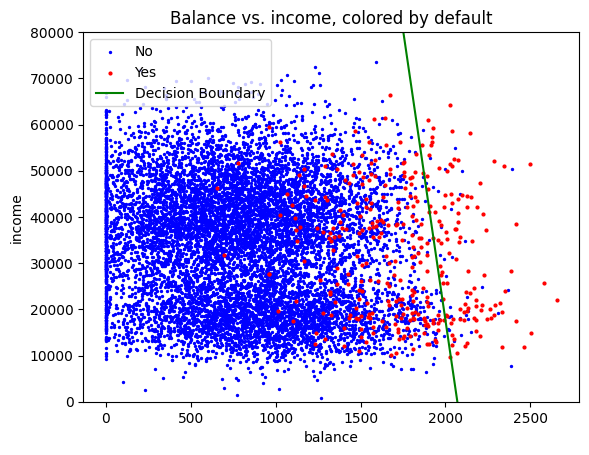

In [6]:
# Plot the decision boundary as a line

# Calculate the slope and intercept of the boundary
# YOUR CODE
b = log_reg.intercept_[0]  
w1, w2 = log_reg.coef_[0]

slope = -w1 / w2
intercept = b / w2
print(f"slope: {slope} \nintercept: {intercept}")

# DO NOT MODIFY THE CODE BELOW
x_points = np.linspace(1500, 2600, 2000)
y_points = slope*x_points - intercept

# Create a scatter plot of (balance, income): red if default is Yes, blue if No
# YOUR CODE
plt.scatter(data_no['balance'], data_no['income'], color='blue', label='No', s=2)
plt.scatter(data_yes['balance'], data_yes['income'], color='red', label='Yes', s=4)

plt.plot(x_points, y_points, color='green', label='Decision Boundary')

plt.ylim(0, 80000)
plt.xlabel('balance')
plt.ylabel('income')
plt.title('Balance vs. income, colored by default')
plt.legend()
plt.show()

4.3) Compute the ROC AUC and plot the ROC curve. (3 pts)

In [7]:
# Function for plotting the ROC curve (DO NOT MODIFY)
def generate_ROCplot(fpr,tpr,label,roc_auc):
    plt.clf()
    plt.plot(fpr, tpr, '.-',label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.0])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver operating characteristic')
    plt.legend(loc="lower right")
    plt.show()

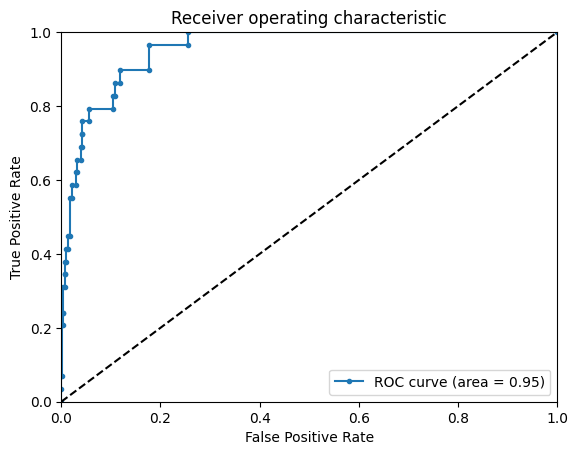

In [8]:
import sklearn.metrics
from sklearn.metrics import roc_curve, auc

# Compute the ROC curve and AUC for the L2-penalized Logistic Regression model
# YOUR CODE
y_scores = log_reg.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

roc_auc = auc(fpr, tpr)

# Plots ROC
generate_ROCplot(fpr,tpr,'LR',roc_auc)

5) Repeat Questions 4.1 through 4.3, this time including the `student` variable as a feature. (10 pts)

In [9]:
X = data[['balance', 'income', 'student_Yes']]
y = data['default_Yes']

# Split the data into training and testing sets
# YOUR CODE
X_train, X_test, y_train, y_test = train_test_split(X, y)

# Train the model
# YOUR CODE
log_reg = LogisticRegression(penalty='l2')
log_reg.fit(X_train, y_train)

# Make predictions on the testing set
# YOUR CODE
log_reg.predict(X_test)

array([0, 0, 0, ..., 0, 0, 0], shape=(2500,))

slope: -1389.4528472808136 
intercept: -2806227.802723495


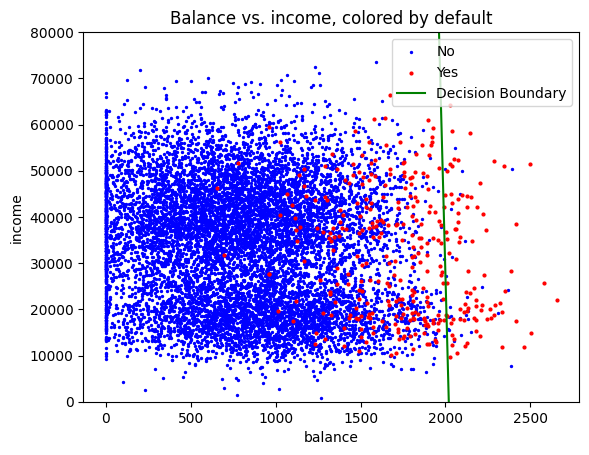

In [10]:
# Plot the decision boundary as a line
# YOUR CODE
b = log_reg.intercept_[0]  
w1, w2, w3 = log_reg.coef_[0]

# finding the decision boundary when student_Yes is fixed to 1
slope = -w1 / w2
intercept = (b + w3) / w2
print(f"slope: {slope} \nintercept: {intercept}")

# DO NOT MODIFY THE CODE BELOW

x_points = np.linspace(1500, 2600, 2000)
y_points = slope*x_points - intercept

# Create a scatter plot of (balance, income): red if default is Yes, blue if No
# YOUR CODE
plt.scatter(data_no['balance'], data_no['income'], color='blue', label='No', s=2)
plt.scatter(data_yes['balance'], data_yes['income'], color='red', label='Yes', s=4)

plt.plot(x_points, y_points, color='green', label='Decision Boundary')

plt.ylim(0, 80000)
plt.xlabel('balance')
plt.ylabel('income')
plt.title('Balance vs. income, colored by default')
plt.legend()
plt.show()

Area under the ROC curve : 0.963046


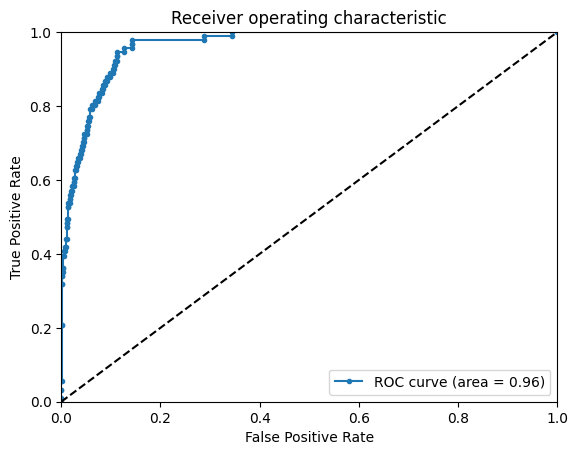

In [11]:
# Compute the ROC AUC
import sklearn.metrics
from sklearn.metrics import roc_curve, auc

# Compute the ROC curve
# YOUR CODE
y_scores = log_reg.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

# Compute the AUC for the L2-penalized Logistic Regression model

# YOUR CODE
roc_auc = auc(fpr, tpr)
print("Area under the ROC curve : %f" % roc_auc)

# Plots ROC
generate_ROCplot(fpr,tpr,'LR',roc_auc)

We observe that performance remains stable after adding the new variable, with the ROC AUC staying around 0.95.

# Part III: Explore Regularization Strengths (Total: 12 pts)

Next, apply Ridge regularization (L2 penalty) with varying strengths to further evaluate the model.

6.1) (5 pts)
* Explore different regularization strengths using a range of `C` values. `C` controls the strength of regularization: smaller values of `C` apply stronger regularization (a larger penalty), while larger values allow the model to fit the training data more closely (a smaller penalty).
* Set `penalty='l2'` and the current `C` value when creating the LogisticRegression object.


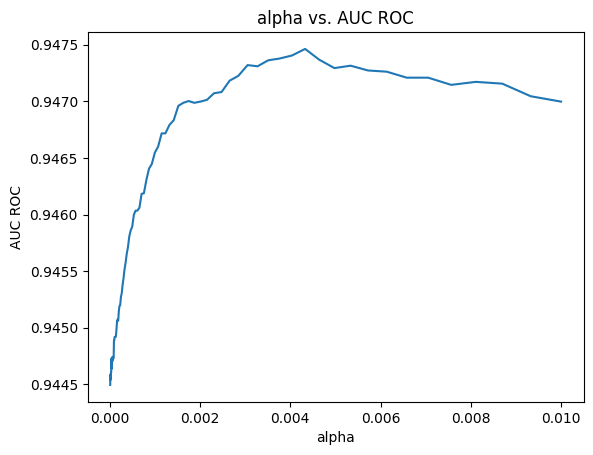

Optimal C value for logistic regression: 0.004328761281083057


In [12]:
from sklearn.metrics import roc_curve, auc
# Optimize using Ridge regularization by adding an L2 penalty to logistic regression

# Define a range of regularization strengths (C values)
C_vals = np.logspace(-5,-2,100)

scores = []

# Scale the data so that feature importance can be compared below
from sklearn.preprocessing import StandardScaler

# YOUR CODE
scalar = StandardScaler()
X_scaled = scalar.fit_transform(X)

# (use random_state=7)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, random_state=7)


# Loop through each C value to evaluate model performance
for C_val in C_vals:


    # Initialize logistic regression model with L2 penalty (Ridge regression) using the current C value
    regr = LogisticRegression(penalty='l2', C=C_val) # YOUR CODE

    # Fit the model to the training data
    regr.fit(X_train, y_train)

    # Predict probabilities for the test set
    probas_ = regr.predict_proba(X_test)[:, 1] # YOUR CODE

    # Calculate the false positive rate (fpr), true positive rate (tpr), and thresholds for ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, probas_) # YOUR CODE

    # Compute the area under the ROC curve (AUC)
    roc_auc = auc(fpr, tpr) # MODIFY THIS CODE

    # Append the AUC score to the scores list for later analysis
    scores.append(roc_auc)

# Plot C values vs. ROC AUC scores
plt.plot(C_vals, scores)
plt.xlabel('alpha')
plt.ylabel('AUC ROC')
plt.title('alpha vs. AUC ROC')
plt.show()

C_best = C_vals[scores.index(max(scores))] # YOUR CODE
print('Optimal C value for logistic regression: ' + str(C_best))

6.2) Compute the coefficients of the logistic regression model using the optimal `C` value you found. (3 pts)

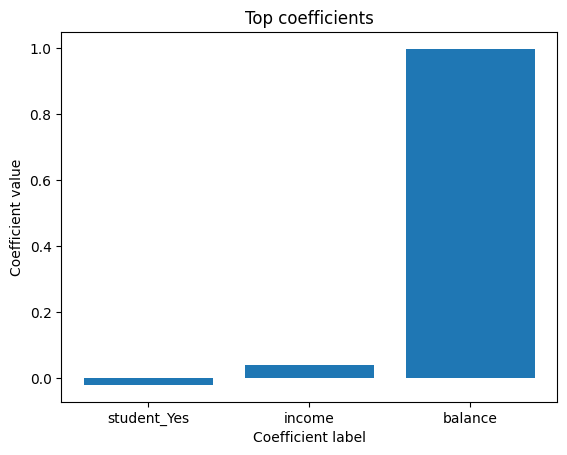

array([-0.01954665,  0.03885394,  0.99780741])

In [13]:
# Fit the model on the training data using the optimal C value and compute the coefficients
regr = LogisticRegression(penalty='l2', C=C_best) # YOUR CODE
regr.fit(X_train,y_train)
coeffs = np.array(regr.coef_[0]) # MODIFY THIS CODE

# Sort and plot the coefficients
# Use Matplotlib to create a bar chart showing the labels and values of the top coefficients.

# Sort the coefficients
# YOUR CODE
sort_index = np.argsort(coeffs)
coeffs = coeffs[sort_index]
X_col_vals = X.columns.values[sort_index]

# Plot
plt.bar(np.array([0,1,2]), coeffs)
plt.xlabel('Coefficient label')
plt.xticks(np.array([0,1,2]), X_col_vals)
plt.ylabel('Coefficient value')
plt.title('Top coefficients')
plt.show()
coeffs

**Question (2 pts):** Based on the plot above, which variable is the most important for predicting the outcome: `balance`, `income`, or `student_Yes`?

ANSWER: Balance appears to be the most important predictor as it has the highest magnitude.

7) Using 5-fold cross-validation, verify that the logistic regression model built with an L2 penalty and the optimal `C` value is robust, meaning it generalizes to other random folds of the dataset. (2 pts)

[0.96037835 0.93489763 0.93078391 0.9449113  0.97432983]


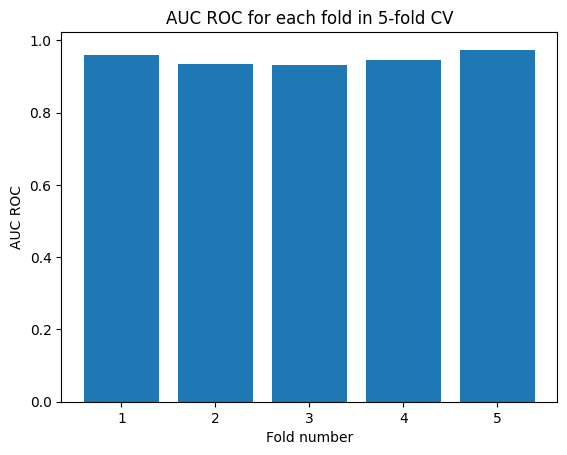

In [14]:
# You may use the built-in scikit-learn function
from sklearn.model_selection import cross_val_score

# Cross-validation
regr = LogisticRegression(penalty='l2', C=C_best) # YOUR CODE: initialize LogisticRegression with penalty='l2' and the optimal C value
regr.fit(X_train, y_train)

scores = cross_val_score(regr, X_train, y_train, cv=5, scoring='roc_auc') # MODIFY THIS CODE
print(scores)
plt.bar(range(1,6),scores)
plt.title('AUC ROC for each fold in 5-fold CV')
plt.xlabel('Fold number')
plt.ylabel('AUC ROC')
plt.show()

**Question (2 pts):** Based on the ROC AUC scores, what can you conclude about the model's ability to generalize to random subsets of the data?

ANSWER: Due to the similar AUC ROC for for each split, largest disparity being 0.931 to 0.974, the model seems to be consistent and generalizes well with random subsets of data.

# End of Assignment